# Teste manual — etapas 1-5 do bounding box cardíaco

Sobe uma imagem **aleatória** do dataset local (`./dataset`, symlink/junction ignorado pelo git),
roda `load_and_preprocess_image` (etapas 1-4: downscale, threshold HU, LCC por fatia),
`compute_geometric_centroid` (etapa 5), e visualiza o resultado para inspeção manual. Também
calcula uma versão preliminar de `Rv` (redução volumétrica) comparando o volume do coração
isolado com o volume da imagem original.

Ver [docs/CODE_NOTES_bounding_box.md](../../docs/CODE_NOTES_bounding_box.md) e
[docs/step5_centroid.md](../../docs/step5_centroid.md) para os detalhes de cada etapa.

In [1]:
# ruff: noqa: E402
import sys
from pathlib import Path

NOTEBOOK_CWD = Path.cwd().resolve()
for candidate in (
    NOTEBOOK_CWD,
    NOTEBOOK_CWD.parent,
    NOTEBOOK_CWD.parent.parent,
):
    src_dir = candidate / "src"
    if src_dir.exists():
        if str(src_dir) not in sys.path:
            sys.path.insert(0, str(src_dir))
        break

from utils.project.notebook_env import configure_notebook_environment  # noqa: E402

REPO_ROOT = configure_notebook_environment()
print(f"REPO_ROOT = {REPO_ROOT}")


REPO_ROOT = G:\DAC\heart-bounding-box


In [2]:
import random

import matplotlib.pyplot as plt
import numpy as np

from utils.project.config import load_config_json
from utils.segmentation.bounding_box import compute_geometric_centroid
from utils.segmentation.pipeline_preprocessing import load_and_preprocess_image
from utils.utils.nifti_io import load_raw_img_and_label
from utils.visualization.image_slices import plot_mip_projection, plot_slices

CONFIG_PATH = REPO_ROOT / "config" / "pipeline_config.json"
DATASET_ROOT = REPO_ROOT / "dataset"

if not DATASET_ROOT.exists():
    raise FileNotFoundError(
        f"Dataset não encontrado em {DATASET_ROOT}. Confirme o symlink/junction 'dataset' "
        "na raiz do repositório (ver .gitignore)."
    )


## 1. Escolher uma imagem aleatória do dataset local

O dataset está organizado em subpastas por faixa de ID (`1-200`, `201-400`, ...), então a busca é
recursiva (`dataset/*/*.img.nii.gz`) em vez de assumir uma pasta única e plana.

In [3]:
img_paths = sorted(DATASET_ROOT.glob("*/*.img.nii.gz"))
print(f"Total de imagens encontradas: {len(img_paths)}")

chosen_path = random.choice(img_paths)
IMG_ID = int(chosen_path.name.split(".")[0])
BASE_PATH = chosen_path.parent

print(f"Imagem escolhida: IMG_ID={IMG_ID}")
print(f"base_path={BASE_PATH}")


Total de imagens encontradas: 1000
Imagem escolhida: IMG_ID=264
base_path=G:\DAC\heart-bounding-box\dataset\201-400


## 2. Rodar o pré-processamento (etapas 1-4)

`load_and_preprocess_image` encadeia downscale → threshold HU adaptativo → LCC por fatia, e
devolve `lcc_image` (volume de intensidades) e `lcc_mask` (máscara binária correspondente).

In [4]:
CONFIG = load_config_json(str(CONFIG_PATH), {})
print("Config:", {
    k: CONFIG[k]
    for k in ("DOWNSCALE_FACTORS", "DOWNSCALE_METHOD", "MIN_THRESHOLD", "MAX_THRESHOLD_PERCENTILE")
})

image_data = load_and_preprocess_image(IMG_ID, str(BASE_PATH), CONFIG)
lcc_image = image_data["lcc_image"]
lcc_mask = image_data["lcc_mask"]
label = image_data["label"]
details = image_data["preprocessing_details"]
spacing = image_data["spacing"]
scaled_spacing = image_data["scaled_spacing"]

print(f"lcc_image: shape={lcc_image.shape} dtype={lcc_image.dtype}")
print(f"lcc_mask:  shape={lcc_mask.shape} dtype={lcc_mask.dtype} voxels={int(lcc_mask.sum())}")
print(f"label:     shape={label.shape} dtype={label.dtype} voxels_artéria={int((label == 1).sum())}")
print(f"spacing original={spacing} | spacing reduzido={scaled_spacing}")
print("preprocessing_details:")
for key, value in details.items():
    print(f"  {key}: {value}")

assert int(lcc_mask.sum()) == details["lcc_voxels"], "lcc_voxels não bate com lcc_mask.sum()"


Config: {'DOWNSCALE_FACTORS': (2, 2, 1), 'DOWNSCALE_METHOD': 'opencv', 'MIN_THRESHOLD': -300, 'MAX_THRESHOLD_PERCENTILE': 99.7}
lcc_image: shape=(256, 256, 231) dtype=float32
lcc_mask:  shape=(256, 256, 231) dtype=bool voxels=10027712
label:     shape=(256, 256, 231) dtype=uint8 voxels_artéria=34281
spacing original=(np.float32(0.35351562), np.float32(0.35351562), np.float32(0.5)) | spacing reduzido=(np.float32(0.70703125), np.float32(0.70703125), np.float32(0.5))
preprocessing_details:
  lower_threshold_method: fixed
  lower_threshold_percentile: None
  lower_threshold_object_percentile: None
  lower_threshold_object_center_hu: None
  lower_threshold_clip_min_hu: -700.0
  lower_threshold_clip_max_hu: 500.0
  min_threshold: -300.0
  max_threshold: 763.25
  threshold_voxels: 10206913
  lcc_voxels: 10027712


## 3. Etapa 5 — centróide geométrico

Coordenadas em `(y, x, z)`, na resolução reduzida (mesma resolução de `lcc_image`/`lcc_mask`).

In [5]:
centroid = compute_geometric_centroid(lcc_mask)
y_c, x_c, z_c = centroid

print(f"Centróide (y, x, z) = ({y_c:.2f}, {x_c:.2f}, {z_c:.2f})")
print(f"Shape do volume     = {lcc_mask.shape}")

assert 0 <= y_c < lcc_mask.shape[0]
assert 0 <= x_c < lcc_mask.shape[1]
assert 0 <= z_c < lcc_mask.shape[2]
print("Centróide dentro dos limites do volume: OK")


Centróide (y, x, z) = (119.04, 138.72, 106.91)
Shape do volume     = (256, 256, 231)
Centróide dentro dos limites do volume: OK


## 4. Redução volumétrica (Rv preliminar)

A tese define, na etapa 9, `Rv = 1 − (V_ROI / V_original)`, comparando o volume do bounding box
**fixo** (etapas 6-8, ainda não implementadas) com o volume da imagem original. Como o envelope de
dimensões máximas ainda não existe, esta seção calcula um **Rv preliminar** usando o volume do
coração isolado pela LCC (`lcc_mask`) como proxy do ROI — útil para ter uma primeira noção de
escala da redução, mas **não é o Rv final da tese** (que será sobre o bbox, não sobre o contorno
exato do coração).

Os volumes são calculados em mm³ (voxels × volume físico do voxel, via `spacing`), não em
contagem bruta de voxels — como o downscale muda o tamanho físico do voxel, comparar contagens
brutas entre a imagem original e a reduzida seria enganoso.

In [6]:
nii_img, _ = load_raw_img_and_label(str(chosen_path))
raw_img = nii_img.get_fdata()

voxel_volume_original_mm3 = float(np.prod(spacing))
voxel_volume_scaled_mm3 = float(np.prod(scaled_spacing))

V_original_mm3 = raw_img.size * voxel_volume_original_mm3
V_full_downscaled_mm3 = lcc_image.size * voxel_volume_scaled_mm3
V_heart_mm3 = int(lcc_mask.sum()) * voxel_volume_scaled_mm3

Rv_heart_preliminar = 1.0 - (V_heart_mm3 / V_original_mm3)

print(f"Shape original (antes do downscale): {raw_img.shape}")
print(f"Shape reduzido (lcc_image):          {lcc_image.shape}")
print()
print(f"Volume da imagem original:           {V_original_mm3 / 1000:,.1f} cm³")
print(f"Volume do grid reduzido (checagem):  {V_full_downscaled_mm3 / 1000:,.1f} cm³  "
      "(deve ≈ original: é resampling, não corte)")
print(f"Volume do coração isolado (LCC):     {V_heart_mm3 / 1000:,.1f} cm³")
print()
print(f"Rv preliminar (coração vs. original): {Rv_heart_preliminar:.2%}")

# Checagem de sanidade: resampling não deveria mudar o volume físico total do grid.
relative_diff = abs(V_full_downscaled_mm3 - V_original_mm3) / V_original_mm3
assert relative_diff < 0.01, (
    f"Volume do grid reduzido diverge {relative_diff:.2%} do original; "
    "esperado ≈0% (só resampling, sem corte)"
)
print("Checagem de sanidade (volume do grid preservado no downscale): OK")


Shape original (antes do downscale): (512, 512, 231)
Shape reduzido (lcc_image):          (256, 256, 231)

Volume da imagem original:           3,783.9 cm³
Volume do grid reduzido (checagem):  3,783.9 cm³  (deve ≈ original: é resampling, não corte)
Volume do coração isolado (LCC):     2,506.4 cm³

Rv preliminar (coração vs. original): 33.76%
Checagem de sanidade (volume do grid preservado no downscale): OK


## 5. Visualização — volume original vs. volume pré-processado (MIP)

Compara a MIP axial da imagem original (resolução integral, antes do downscale) com a MIP do
`lcc_image` final (resolução reduzida, após downscale + threshold + LCC).

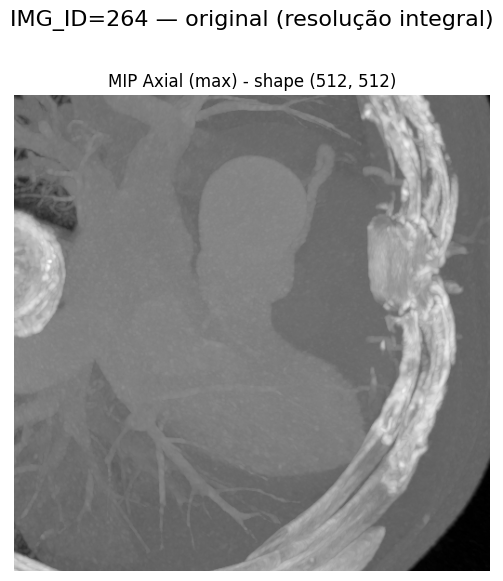

In [7]:
plot_mip_projection(
    raw_img,
    title=f"IMG_ID={IMG_ID} — original (resolução integral)",
    views=["axial"],
)


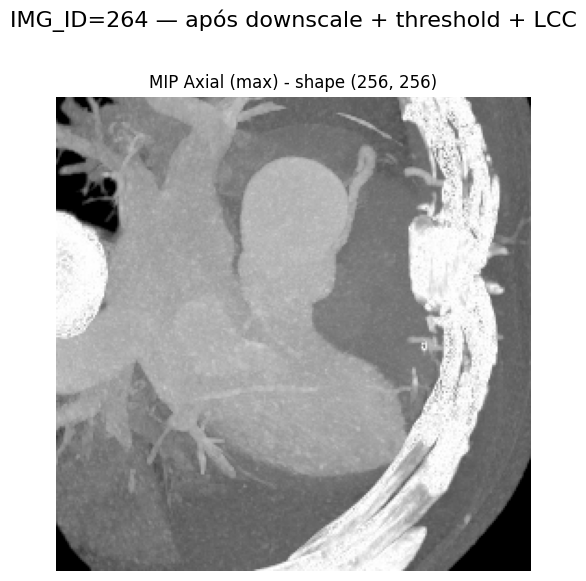

In [8]:
plot_mip_projection(
    lcc_image,
    title=f"IMG_ID={IMG_ID} — após downscale + threshold + LCC",
    views=["axial"],
)


## 6. Fatias axiais amostradas do volume LCC

Inspeção visual rápida da qualidade da LCC (deve mostrar só o coração/grandes vasos, sem pulmões
ou estruturas isoladas).

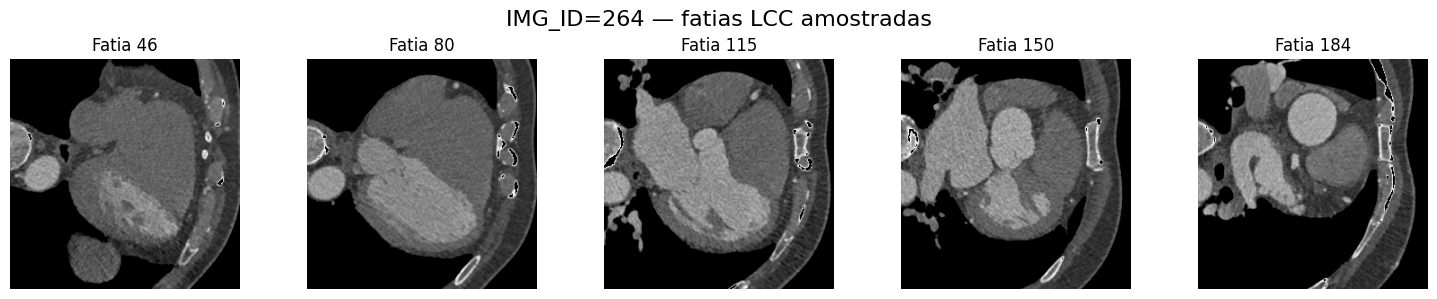

In [9]:
num_slices = lcc_image.shape[2]
sample_indices = sorted(set(
    int(round(frac * (num_slices - 1))) for frac in (0.2, 0.35, 0.5, 0.65, 0.8)
))
plot_slices(lcc_image, sample_indices, title=f"IMG_ID={IMG_ID} — fatias LCC amostradas")


## 7. Centróide sobreposto na fatia correspondente

Marca `(x_c, y_c)` na fatia axial mais próxima de `z_c`, para conferir visualmente que o centróide
cai dentro da região cardíaca (e não, por exemplo, deslocado por uma troca de eixos).

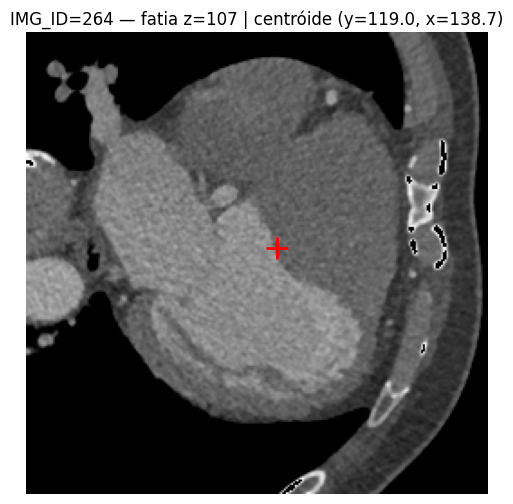

In [10]:
z_slice = int(round(z_c))

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(lcc_image[:, :, z_slice], cmap="gray")
ax.plot(x_c, y_c, "r+", markersize=16, markeredgewidth=2)
ax.set_title(f"IMG_ID={IMG_ID} — fatia z={z_slice} | centróide (y={y_c:.1f}, x={x_c:.1f})")
ax.axis("off")
plt.show()


## 8. Contexto anatômico — MIP do label (artéria coronária)

Apenas para referência visual: mostra onde a artéria rotulada está em relação ao volume cardíaco,
já na mesma resolução reduzida (o label também passa por downscale em `load_and_preprocess_image`,
com interpolação nearest-neighbor para preservar classes).

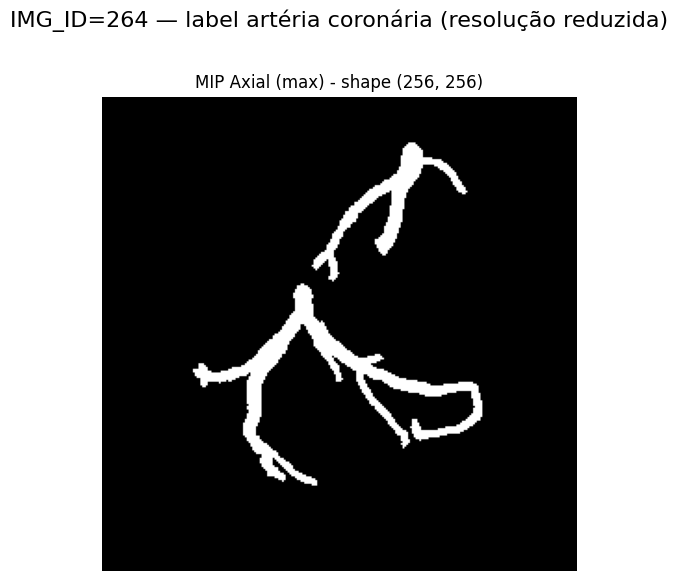

In [11]:
label_artery = (label == 1).astype("uint8")

if label_artery.sum() > 0:
    plot_mip_projection(
        label_artery,
        title=f"IMG_ID={IMG_ID} — label artéria coronária (resolução reduzida)",
        views=["axial"],
    )
else:
    print("Label sem voxels de artéria após downscale (raro, mas possível em labels muito finos).")


## 9. Resumo

Se todas as células acima rodaram sem erro e as visualizações fazem sentido anatomicamente
(coração isolado na MIP/fatias, centróide dentro da região cardíaca, Rv preliminar numa faixa
plausível), as etapas 1-5 estão funcionando como esperado para esta imagem. Rode o notebook de
novo para sortear outra imagem.

In [12]:
print(f"IMG_ID testado: {IMG_ID}")
print(f"Voxels LCC: {int(lcc_mask.sum())} de {lcc_mask.size} ({100 * lcc_mask.mean():.2f}% do grid reduzido)")
print(f"Centróide (y, x, z): ({y_c:.2f}, {x_c:.2f}, {z_c:.2f})")
print(f"Rv preliminar (coração vs. imagem original): {Rv_heart_preliminar:.2%}")
print("Todas as verificações (asserts) das células acima passaram.")


IMG_ID testado: 264
Voxels LCC: 10027712 de 15138816 (66.24% do grid reduzido)
Centróide (y, x, z): (119.04, 138.72, 106.91)
Rv preliminar (coração vs. imagem original): 33.76%
Todas as verificações (asserts) das células acima passaram.
